# Atividade Prática: Introdução à Modelagem Estatística e Análise de Regressão Simples

# ATIVIDADE 1
- Utilize o conjunto de dados a seguir para montar um gráfico de dispersão:

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Horas de Treinamento' : [5.2, 5.1, 4.9, 4.6, 4.7, 4.8, 4.6, 4.9],
    'Tempo para completar o trabalho' : [13, 15, 16, 20, 19, 17, 21, 16]
}

In [3]:
df = pd.DataFrame(data)

In [4]:
print(df)

   Horas de Treinamento  Tempo para completar o trabalho
0                   5.2                               13
1                   5.1                               15
2                   4.9                               16
3                   4.6                               20
4                   4.7                               19
5                   4.8                               17
6                   4.6                               21
7                   4.9                               16


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 2 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Horas de Treinamento             8 non-null      float64
 1   Tempo para completar o trabalho  8 non-null      int64  
dtypes: float64(1), int64(1)
memory usage: 260.0 bytes
None


In [6]:
df.dtypes

,0
Horas de Treinamento,float64
Tempo para completar o trabalho,int64


In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df.isnull().sum()

,0
Horas de Treinamento,0
Tempo para completar o trabalho,0


- Determine o modelo de regressão linear simples entre as variáveis x e y, sendo y a variável resposta e determine a reta de regressão.

Definir Variáveis Independentes e Dependentes:

Vamos prever o Tempo para completar o trabalho baseado nas Horas de Treinamento.

In [9]:
x = df.drop('Tempo para completar o trabalho', axis='columns')
y = df['Tempo para completar o trabalho']

In [10]:
model = LinearRegression()
model.fit(x, y)

LinearRegression()

In [11]:
y_pred = model.predict(x)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print(f'R²: {r2}')

R²: 0.9482584188466544


Visualizar os Resultados

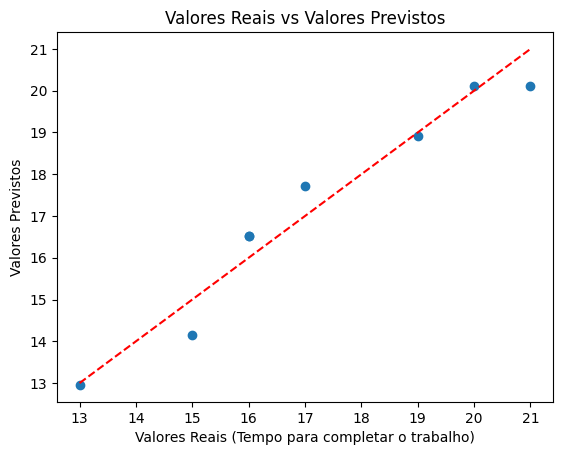

In [12]:
plt.scatter(y, y_pred)
plt.xlabel('Valores Reais (Tempo para completar o trabalho)')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()

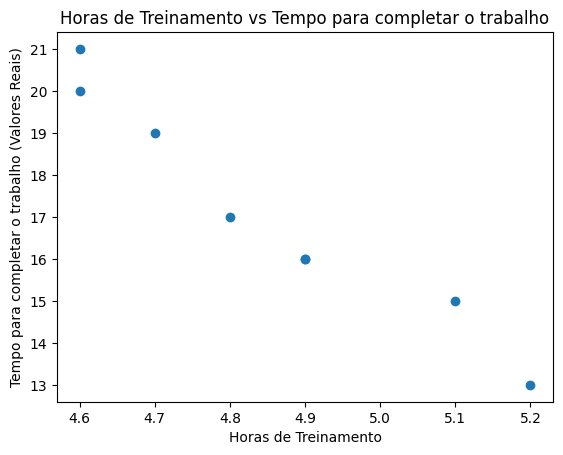

In [13]:
plt.scatter(x, y)
plt.xlabel('Horas de Treinamento')
plt.ylabel('Tempo para completar o trabalho (Valores Reais)')
plt.title('Horas de Treinamento vs Tempo para completar o trabalho')
plt.show()

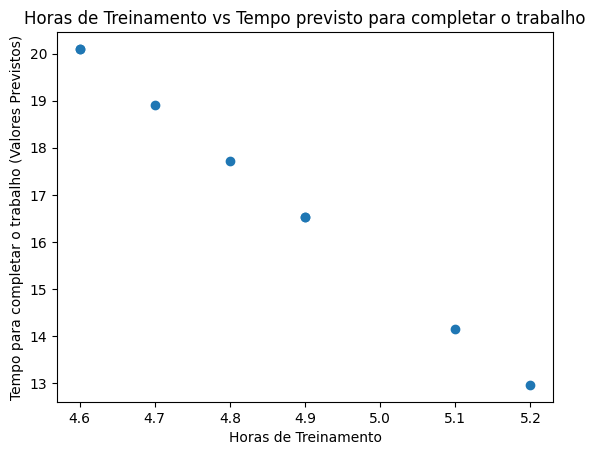

In [14]:
plt.scatter(x, y_pred)
plt.xlabel('Horas de Treinamento')
plt.ylabel('Tempo para completar o trabalho (Valores Previstos)')
plt.title('Horas de Treinamento vs Tempo previsto para completar o trabalho')
plt.show()

- Faça uma análise do modelo de regressão.

O modelo de Regressão Linear criado aqui, embora tenha poucos dados, foi capaz de atingir uma precisão de aproximadamente 94.8% (de acordo com a métrica R quadrado).

Portanto, as previsões do tempo para completar o trabalho baseado nas horas de treinamento chegam muito perto do que realmente aconteceu na nossa base de dados.

# ATIVIDADE 2

Na atividade de hoje, vocês utilizarão as bases de dados Student Performance (https://archive.ics.uci.edu/dataset/320/student+performance) e Insurance Data (https://www.kaggle.com/datasets/moneystore/agencyperformance?resource=download). Para ambas vocês deverão realizar uma análise exploratória de dados inicial, e:

- Criar um dicionário de dados, para entender o significado o tipo de cada variável

#Análise Exploratória Inicial na base Student Performance
A base de dados Student Performance tem duas tabelas em CSV

In [15]:
math_df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/Mackenzie/4Semestre/AnaliseDeDados/Aula6/student-mat.csv', sep=';')
por_df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/Mackenzie/4Semestre/AnaliseDeDados/Aula6/student-por.csv', sep=';')

In [16]:
print('Dataframe de Matemática:')
print(math_df.head())

print('\nDataframe de Português:')
print(por_df.head())

Dataframe de Matemática:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

Dataframe de Português:
  school sex  age address famsize Psta

In [17]:
print('Dataframe de Matemática:')
print(math_df.tail())

print('\nDataframe de Português:')
print(por_df.tail())

Dataframe de Matemática:
    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
390  ...      5        5      4     4     5      4       11   9   9   9  
391  ...      2        4      5     3     4      2        3  14  16  16  
392  ...      5        5      3     3     3      3        3  10   8   7  
393  ...      4        4      1     3     4      5        0  11  12  10  
394  ...      3        2      3     3     3      5        5   8   9   9  

[5 rows x 33 columns]

Dataframe de Português:
    scho

In [18]:
print(math_df.info())

print('\n', math_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [19]:
print(por_df.info())

print('\n', por_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [20]:
print(math_df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [21]:
print(por_df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [22]:
print('Linhas duplicadas no Dataframe de Matemática:', math_df.duplicated().sum())
print('Linhas duplicadas no Dataframe de Português:', por_df.duplicated().sum())

Linhas duplicadas no Dataframe de Matemática: 0
Linhas duplicadas no Dataframe de Português: 0


# Dicionário de Dados para as tabelas do dataset Student Performance

| Variável | Descrição | Tipo | Mensuração | Valores |
| :--- | :--- | :--- | :--- | :--- |
| **school** | Escola do aluno. | Categórico | Texto | 'GP' (Gabriel Pereira) ou 'MS' (Mousinho da Silveira) |
| **sex** | Sexo do aluno. | Categórico (Binário) | Texto | 'F' (Feminino) ou 'M' (Masculino) |
| **age** | Idade do aluno. | Inteiro | Anos | 15 a 22 |
| **address** | Tipo de endereço residencial. | Categórico | Texto | 'U' (Urbano) ou 'R' (Rural) |
| **famsize** | Tamanho da família. | Categórico | Texto | 'LE3' (<= 3) ou 'GT3' (> 3) |
| **Pstatus** | Status de coabitação dos pais. | Categórico | Texto | 'T' (Juntos) ou 'A' (Separados) |
| **Medu** | Nível de escolaridade da mãe. | Inteiro | Nível (Escala) | 0 (Nenhuma) a 4 (Ensino Superior) |
| **Fedu** | Nível de escolaridade do pai. | Inteiro | Nível (Escala) | 0 (Nenhuma) a 4 (Ensino Superior) |
| **Mjob** | Profissão da mãe. | Categórico | Texto | 'teacher', 'health', 'services', 'at_home', 'other' |
| **Fjob** | Profissão do pai. | Categórico | Texto | 'teacher', 'health', 'services', 'at_home', 'other' |
| **reason** | Motivo para escolher a escola. | Categórico | Texto | 'home', 'reputation', 'course', 'other' |
| **guardian** | Responsável legal pelo aluno. | Categórico | Texto | 'mother', 'father' ou 'other' |
| **traveltime** | Tempo de viagem de casa para a escola. | Inteiro | Tempo (Escala) | 1 (<15 min) a 4 (>1 hora) |
| **studytime** | Tempo de estudo semanal. | Inteiro | Tempo (Escala) | 1 (<2 horas) a 4 (>10 horas) |
| **failures** | Número de reprovações anteriores. | Inteiro | Quantidade | 0 a 4 |
| **schoolsup** | Suporte educacional extra. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **famsup** | Suporte educacional da família. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **paid** | Aulas particulares pagas na disciplina. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **activities** | Atividades extracurriculares. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **nursery** | Frequentou a creche/escola maternal. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **higher** | Deseja cursar o ensino superior. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **internet** | Acesso à internet em casa. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **romantic** | Em um relacionamento amoroso. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **famrel** | Qualidade das relações familiares. | Inteiro | Escala de 1 a 5 | 1 (muito ruim) a 5 (excelente) |
| **freetime** | Tempo livre após a escola. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **goout** | Frequência de saídas com amigos. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **Dalc** | Consumo de álcool em dias úteis. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **Walc** | Consumo de álcool aos finais de semana. | Inteiro | Escala de 1 a 5 | 1 (muito baixo) a 5 (muito alto) |
| **health** | Estado de saúde atual. | Inteiro | Escala de 1 a 5 | 1 (muito ruim) a 5 (muito bom) |
| **absences** | Número de faltas escolares. | Inteiro | Quantidade | 0 a 93 |
| **G1** | Nota do 1º período. | Inteiro | Nota (Pontos) | 0 a 20 |
| **G2** | Nota do 2º período. | Inteiro | Nota (Pontos) | 0 a 20 |
| **G3** | Nota final (variável alvo). | Inteiro | Nota (Pontos) | 0 a 20 |

# Sobre o Dataset Student Performance



## Análise Descritiva:

### Quais são as principais variáveis no dataset e como elas se relacionam com as notas finais dos alunos?

- As principais variáveis são: address, famsize, Pstatus, Medu, Fedu, reason, traveltime, studytime, failures, schoolsup, famsup, paid, activities, nursery, higher, internet, romantic, freetime, goout, Dalc, health, absences  

A nota G1 tem uma correlação praticamente linear em um scatterplot com a G3, portanto é possível afirmar que o desempenho no primeiro ano influencia fortemente no desempenho final.

O desejo de cursar ensino superior (Sim ou Não) tambêm tem grande influência nas notas finais obtidas

O número de reprovações anteriores também impactou bastante nas notas, e os alunos com menos reprovações tiveram as melhores notas.

O tempo de viagem até a escola não influencia tanto na nota final dos alunos.

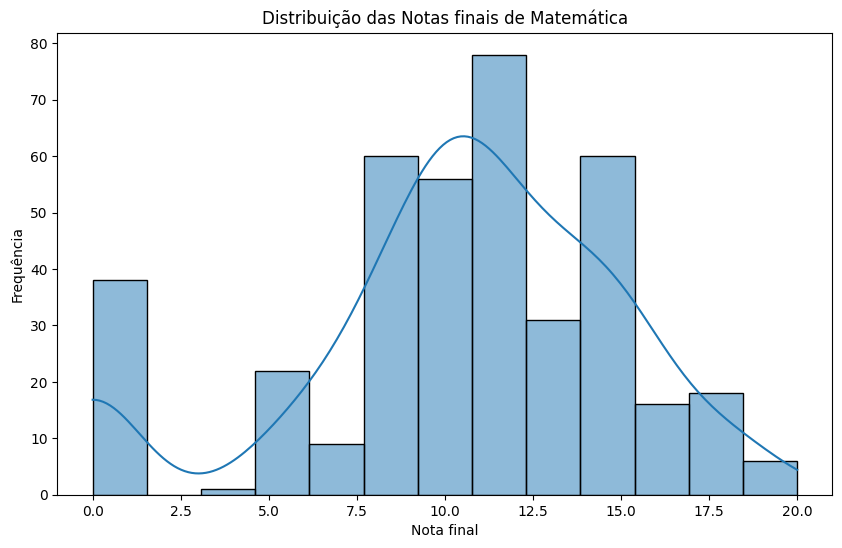

In [23]:
# Histograma da variável 'G3' de Matemática
plt.figure(figsize=(10, 6))
sns.histplot(math_df['G3'], kde=True)
plt.title('Distribuição das Notas finais de Matemática')
plt.xlabel('Nota final')
plt.ylabel('Frequência')
plt.show()

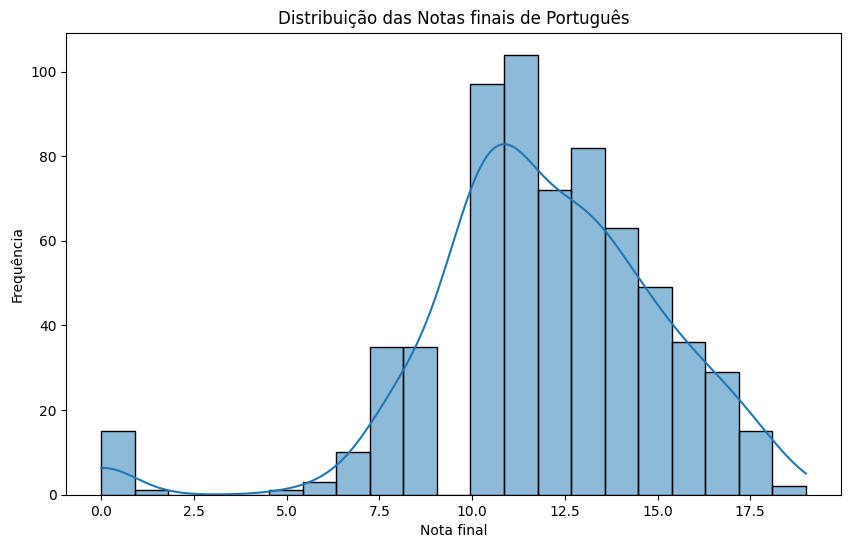

In [24]:
# Histograma da variável 'G3' de Português
plt.figure(figsize=(10, 6))
sns.histplot(por_df['G3'], kde=True)
plt.title('Distribuição das Notas finais de Português')
plt.xlabel('Nota final')
plt.ylabel('Frequência')
plt.show()

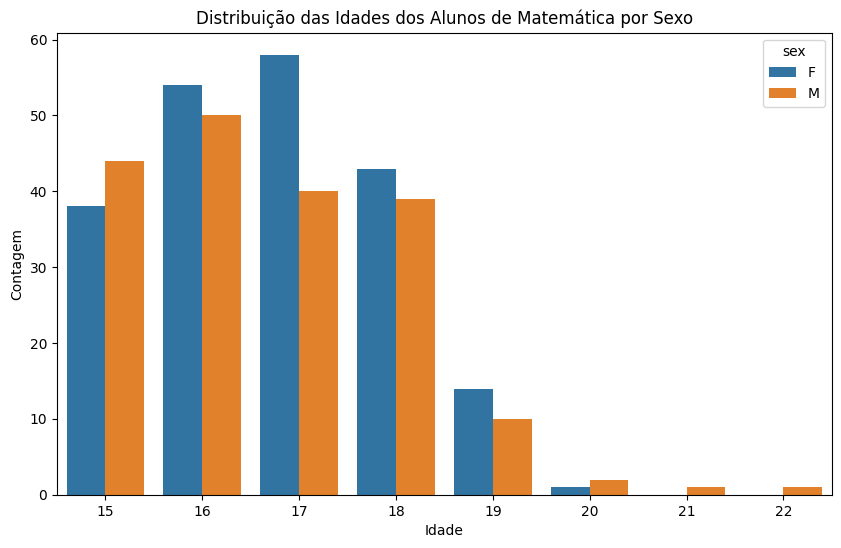

In [25]:
# Contagem das idades
plt.figure(figsize=(10, 6))
sns.countplot(x='age', data=math_df, hue='sex')
plt.title('Distribuição das Idades dos Alunos de Matemática por Sexo')
plt.xlabel('Idade')
plt.ylabel('Contagem')
plt.show()

# Tem mais mulheres do que homens!

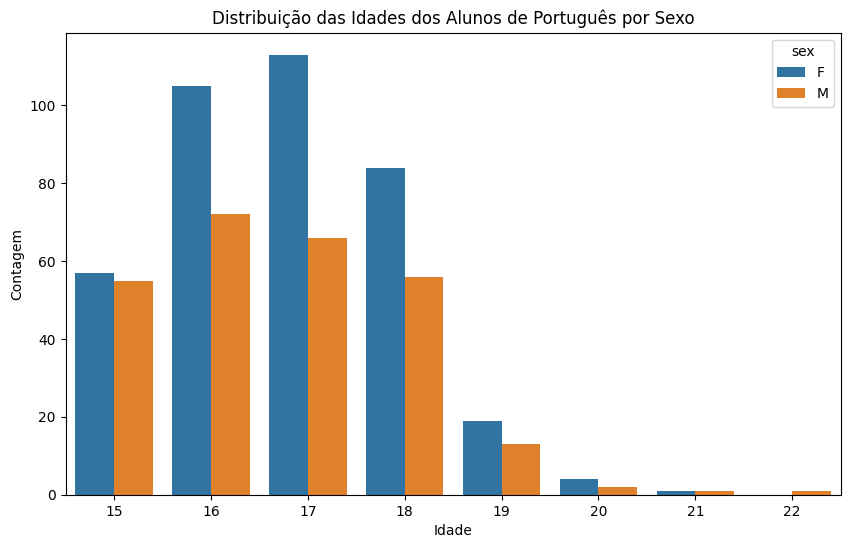

In [26]:
# Contagem das idades
plt.figure(figsize=(10, 6))
sns.countplot(x='age', data=por_df, hue='sex')
plt.title('Distribuição das Idades dos Alunos de Português por Sexo')
plt.xlabel('Idade')
plt.ylabel('Contagem')
plt.show()

# Tem muito mais mulheres do que homens!

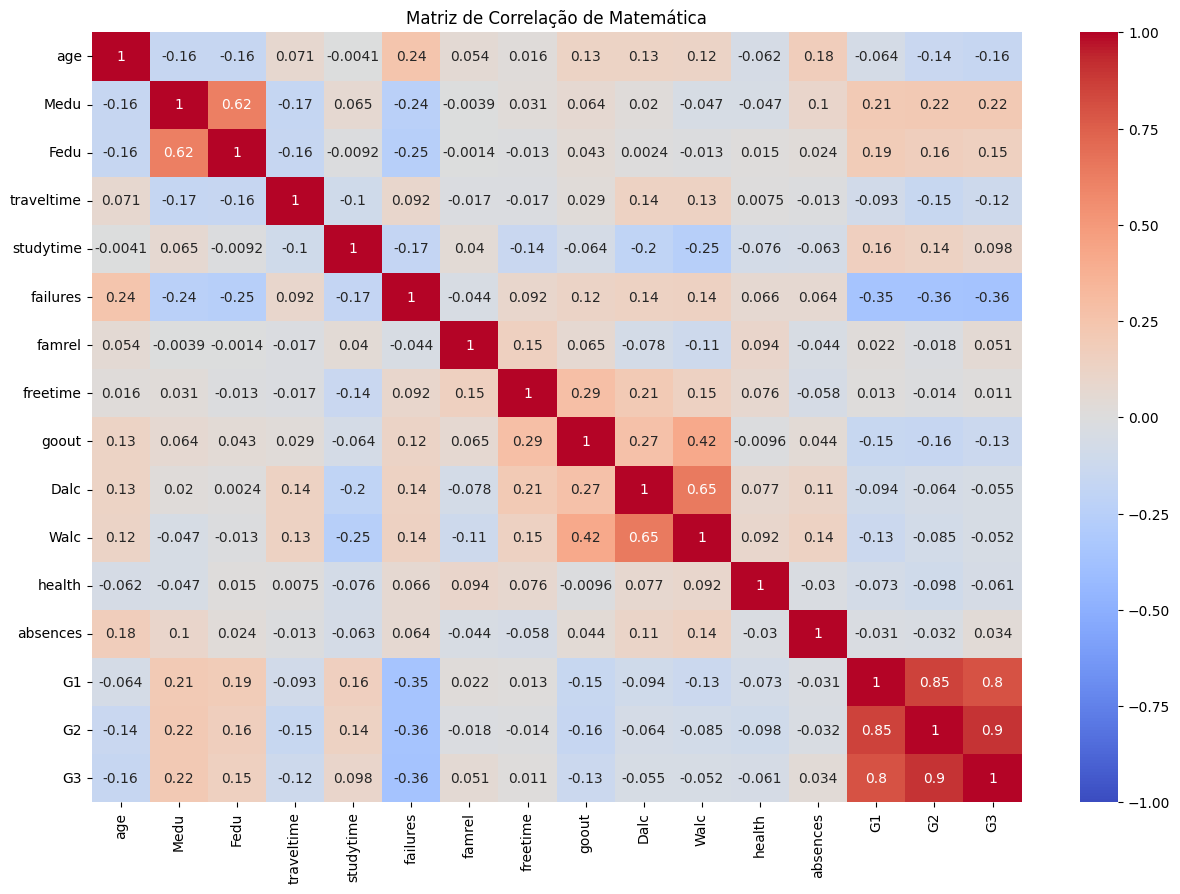

In [27]:
# Calcular e visualizar a matriz de correlação de Matemática
plt.figure(figsize=(15, 10))
corr = math_df[['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Matemática')
plt.show()


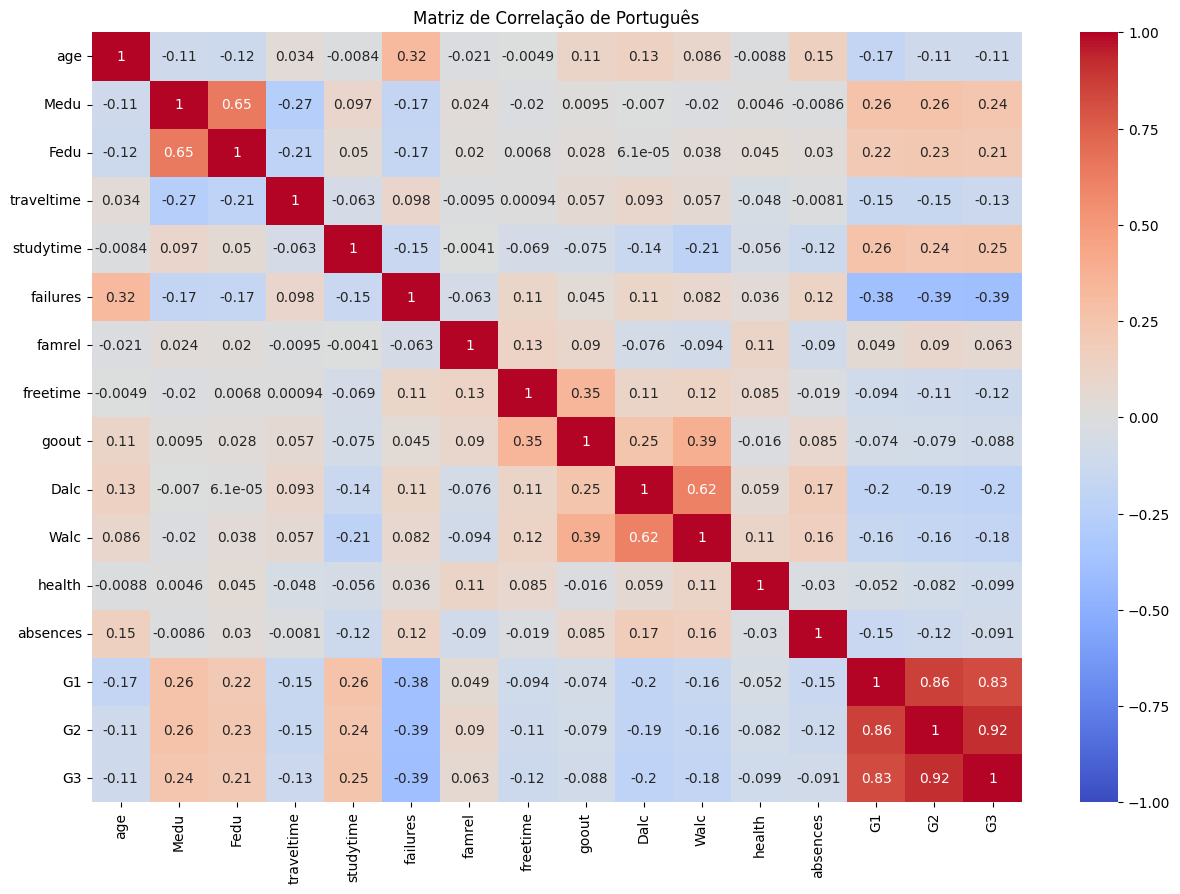

In [28]:
# Calcular e visualizar a matriz de correlação de Português
plt.figure(figsize=(15, 10))
corr = por_df[['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Português')
plt.show()

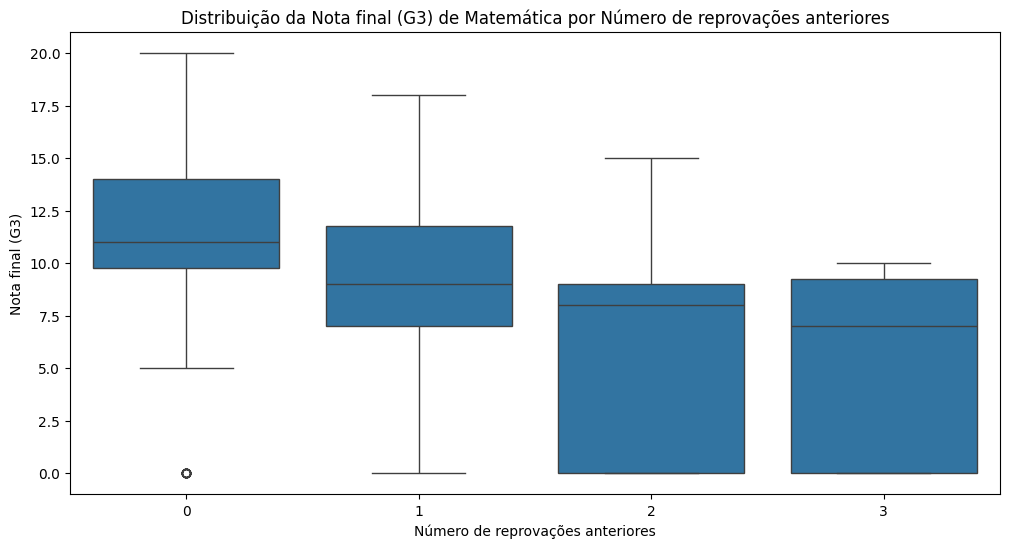

In [29]:
# Nota dos alunos por Numero de reprovacoes em Matemática
plt.figure(figsize=(12, 6))
sns.boxplot(x='failures', y='G3', data=math_df)
plt.title('Distribuição da Nota final (G3) de Matemática por Número de reprovações anteriores')
plt.xlabel('Número de reprovações anteriores')
plt.ylabel('Nota final (G3)')
plt.show()
# quanto menor o número de reprovações dos alunos, maior foi a mediana das notas finais em Matemática!


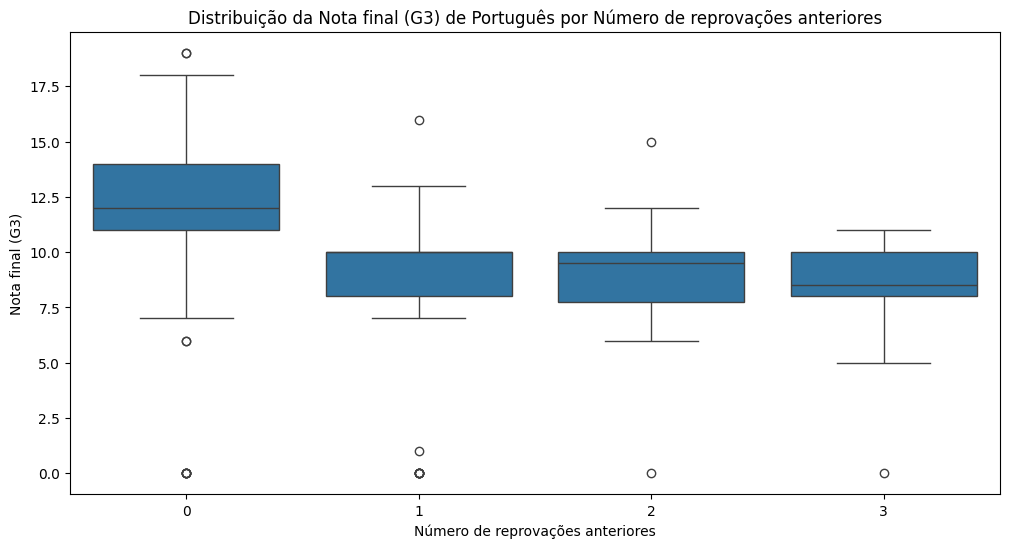

In [30]:
# Nota dos alunos por Numero de reprovacoes em Português
plt.figure(figsize=(12, 6))
sns.boxplot(x='failures', y='G3', data=por_df)
plt.title('Distribuição da Nota final (G3) de Português por Número de reprovações anteriores')
plt.xlabel('Número de reprovações anteriores')
plt.ylabel('Nota final (G3)')
plt.show()
# quanto menor o número de reprovações dos alunos, maior foi a mediana das
# notas finais em Português também!


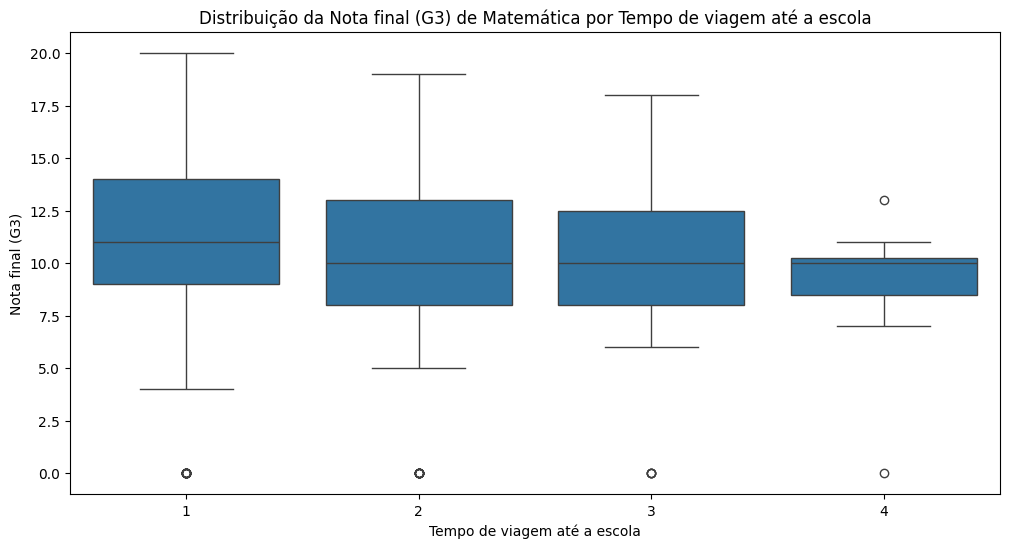

In [31]:
# Nota dos alunos por Tempo de viagem até a escola
plt.figure(figsize=(12, 6))
sns.boxplot(x='traveltime', y='G3', data=math_df)
plt.title('Distribuição da Nota final (G3) de Matemática por Tempo de viagem até a escola')
plt.xlabel('Tempo de viagem até a escola')
plt.ylabel('Nota final (G3)')
plt.show()
# numeric: 1 - <15 min., 2 - 15 to 30 min., 3 - 30 min. to 1 hour, or 4 - >1 hour
# o tempo de viagem não influenciou tanto nas notas de Matemática

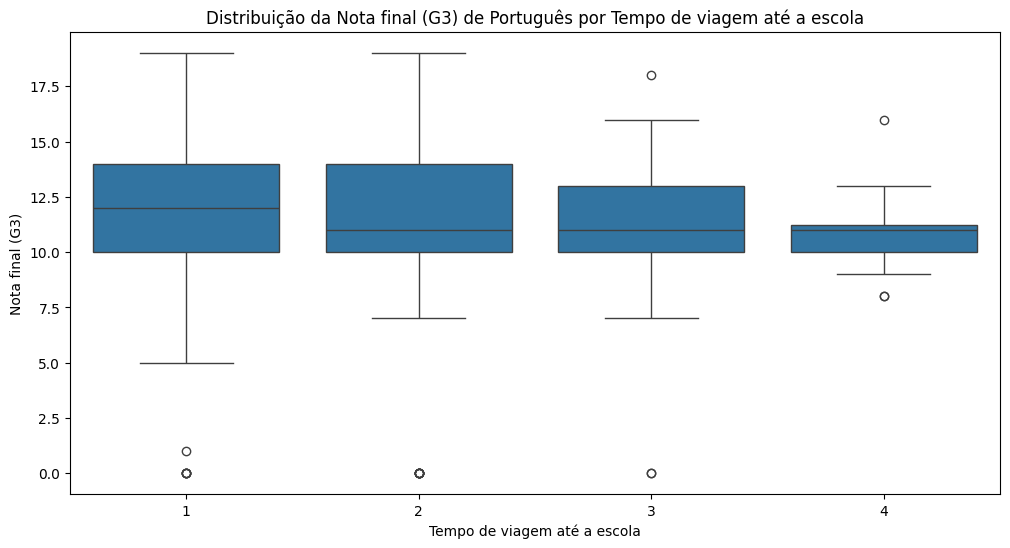

In [32]:
# Nota dos alunos por Tempo de viagem até a escola
plt.figure(figsize=(12, 6))
sns.boxplot(x='traveltime', y='G3', data=por_df)
plt.title('Distribuição da Nota final (G3) de Português por Tempo de viagem até a escola')
plt.xlabel('Tempo de viagem até a escola')
plt.ylabel('Nota final (G3)')
plt.show()
# numeric: 1 - <15 min., 2 - 15 to 30 min., 3 - 30 min. to 1 hour, or 4 - >1 hour
# o tempo de viagem não influenciou tanto nas notas de Português

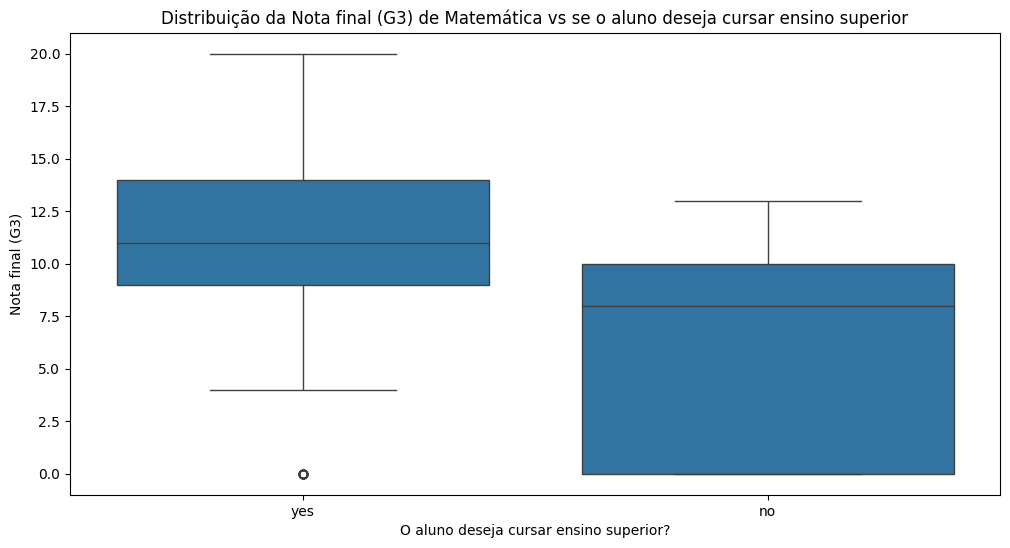

In [33]:
# Nota de Matemática dos alunos por O aluno deseja cursar ensino superior
plt.figure(figsize=(12, 6))
sns.boxplot(x='higher', y='G3', data=math_df)
plt.title('Distribuição da Nota final (G3) de Matemática vs se o aluno deseja cursar ensino superior')
plt.xlabel('O aluno deseja cursar ensino superior?')
plt.ylabel('Nota final (G3)')
plt.show()
# aqui consegui uma relação interessante

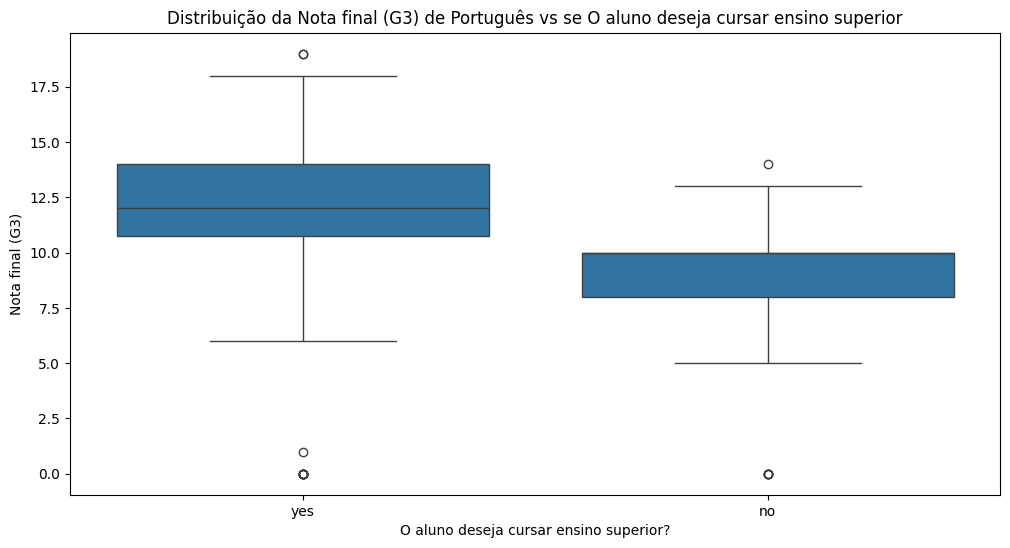

In [34]:
# Nota de Português dos alunos por O aluno deseja cursar ensino superior
plt.figure(figsize=(12, 6))
sns.boxplot(x='higher', y='G3', data=por_df)
plt.title('Distribuição da Nota final (G3) de Português vs se O aluno deseja cursar ensino superior')
plt.xlabel('O aluno deseja cursar ensino superior?')
plt.ylabel('Nota final (G3)')
plt.show()
# aqui consegui uma relação interessante

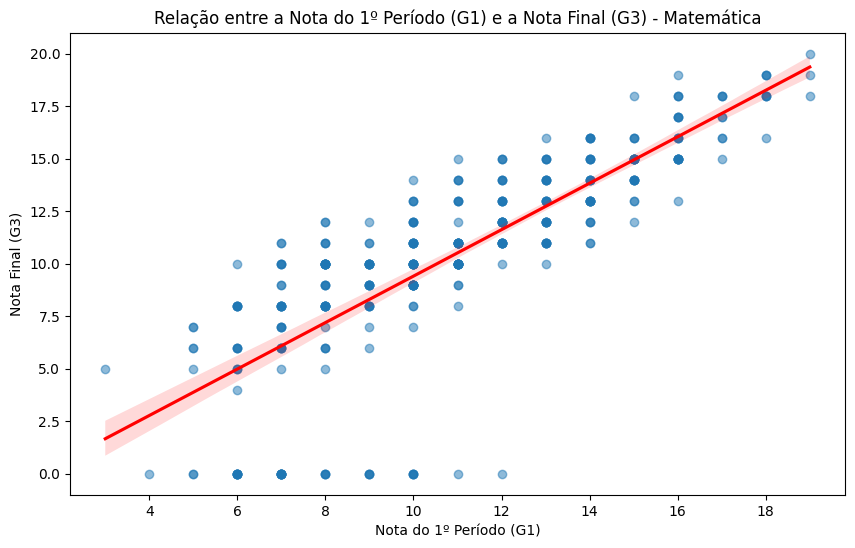

In [35]:
# Gráfico de dispersão com linha de regressão: G1 vs G3 (Matemática)
plt.figure(figsize=(10, 6))
sns.regplot(x='G1', y='G3', data=math_df,
            scatter_kws={'alpha': 0.5}, # alpha deixa os pontos translúcidos para ver sobreposições
            line_kws={'color': 'red'})  # linha de tendência em vermelho

plt.title('Relação entre a Nota do 1º Período (G1) e a Nota Final (G3) - Matemática')
plt.xlabel('Nota do 1º Período (G1)')
plt.ylabel('Nota Final (G3)')
plt.show()

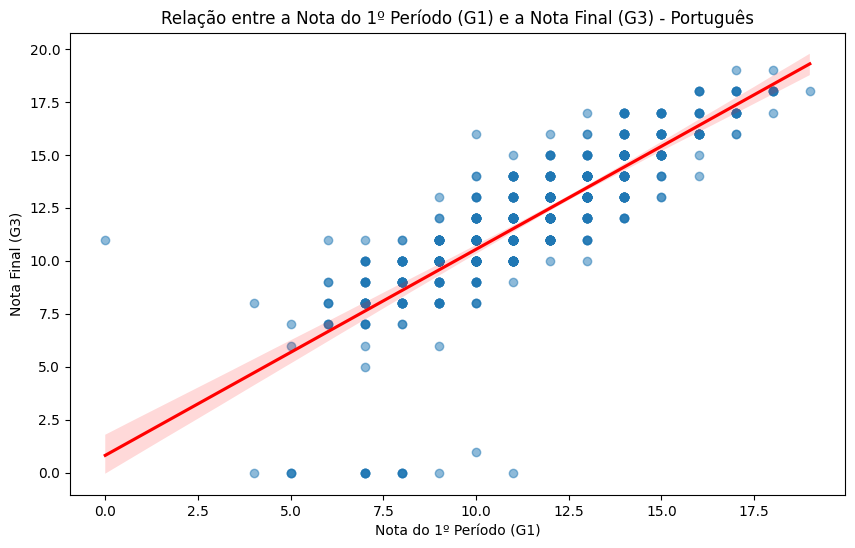

In [36]:
# Gráfico de dispersão com linha de regressão: G1 vs G3 (Português)
plt.figure(figsize=(10, 6))
sns.regplot(x='G1', y='G3', data=por_df,
            scatter_kws={'alpha': 0.5}, # alpha deixa os pontos translúcidos para ver sobreposições
            line_kws={'color': 'red'})  # linha de tendência em vermelho

plt.title('Relação entre a Nota do 1º Período (G1) e a Nota Final (G3) - Português')
plt.xlabel('Nota do 1º Período (G1)')
plt.ylabel('Nota Final (G3)')
plt.show()

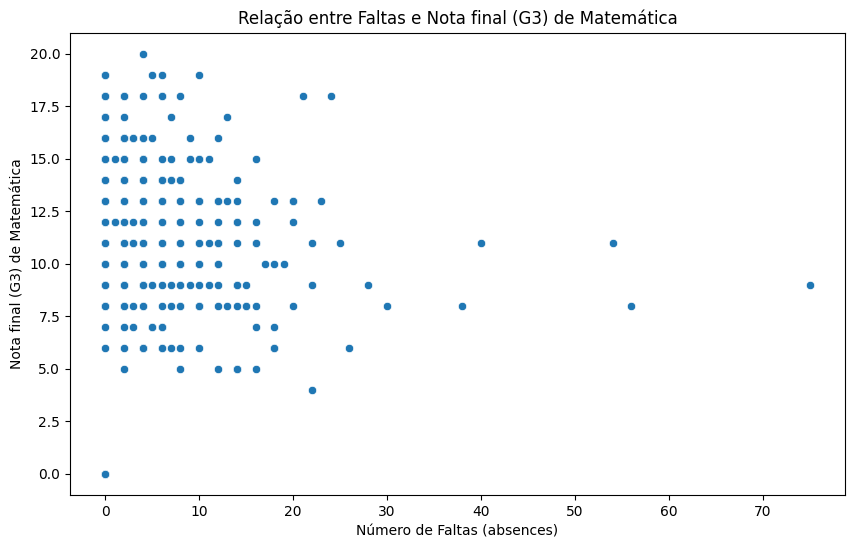

In [37]:
# Relação entre Faltas e G3 de Matemática
plt.figure(figsize=(10, 6))
sns.scatterplot(x='absences', y='G3', data=math_df)
plt.title('Relação entre Faltas e Nota final (G3) de Matemática')
plt.xlabel('Número de Faltas (absences)')
plt.ylabel('Nota final (G3) de Matemática')
plt.show()
# a maioria dos alunos se concentra na faixa de poucas faltas

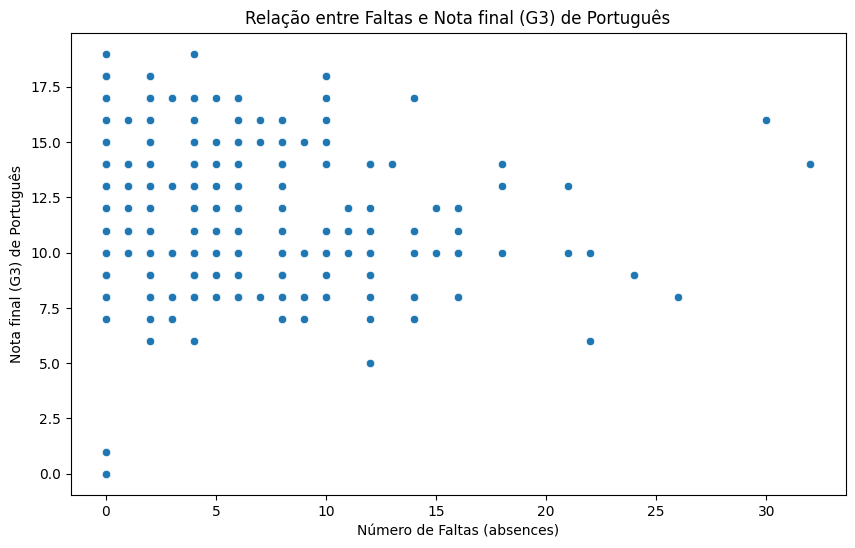

In [38]:
# Relação entre Faltas e G3 de Português
plt.figure(figsize=(10, 6))
sns.scatterplot(x='absences', y='G3', data=por_df)
plt.title('Relação entre Faltas e Nota final (G3) de Português')
plt.xlabel('Número de Faltas (absences)')
plt.ylabel('Nota final (G3) de Português')
plt.show()
# neste caso, o numero de faltas esta bem disperso

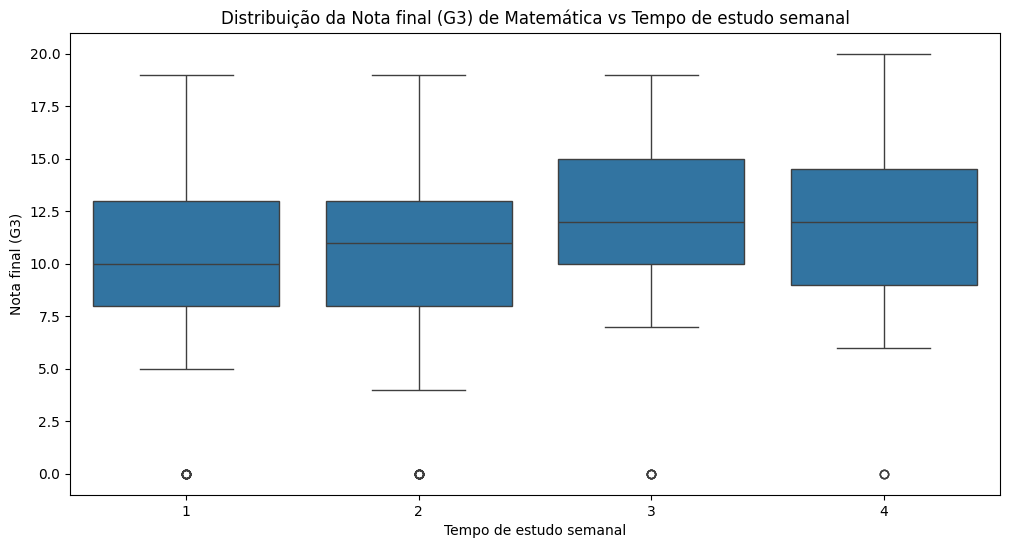

In [39]:
# Nota de Matemática dos alunos vs Tempo de estudo semanal
plt.figure(figsize=(12, 6))
sns.boxplot(x='studytime', y='G3', data=math_df)
plt.title('Distribuição da Nota final (G3) de Matemática vs Tempo de estudo semanal')
plt.xlabel('Tempo de estudo semanal')
plt.ylabel('Nota final (G3)')
plt.show()
# horas de estudo vai de 1 a 4:
# 1 (<2 hours), 2 (2 to 5 hours), 3 (5 to 10 hours), or 4  (>10 hours)

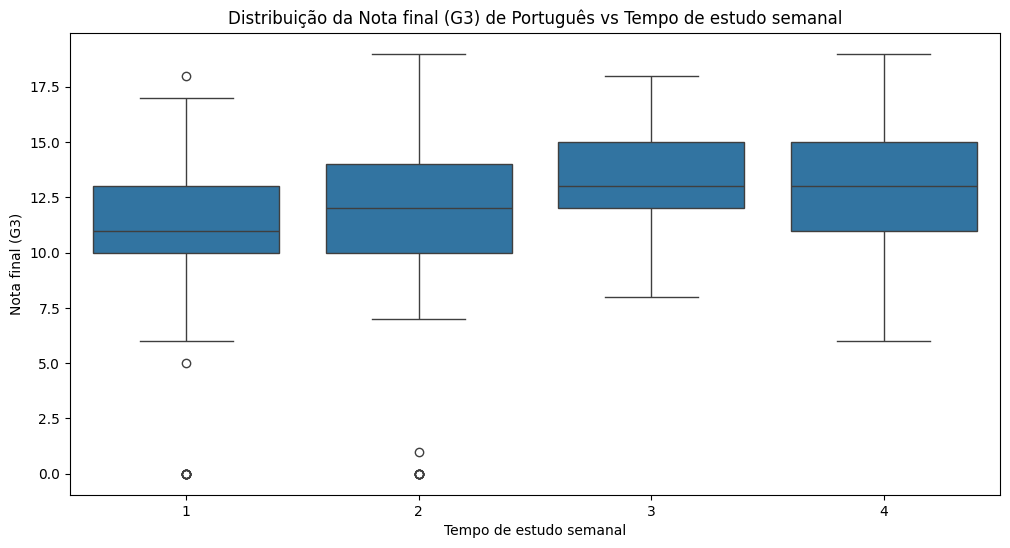

In [40]:
# Nota de Português dos alunos vs Tempo de estudo semanal
plt.figure(figsize=(12, 6))
sns.boxplot(x='studytime', y='G3', data=por_df)
plt.title('Distribuição da Nota final (G3) de Português vs Tempo de estudo semanal')
plt.xlabel('Tempo de estudo semanal')
plt.ylabel('Nota final (G3)')
plt.show()
# horas de estudo vai de 1 a 4:
# 1 (<2 hours), 2 (2 to 5 hours), 3 (5 to 10 hours), or 4  (>10 hours)

/tmp/ipykernel_1944/2858401079.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='studytime', y='G3', data=math_df, palette='muted')


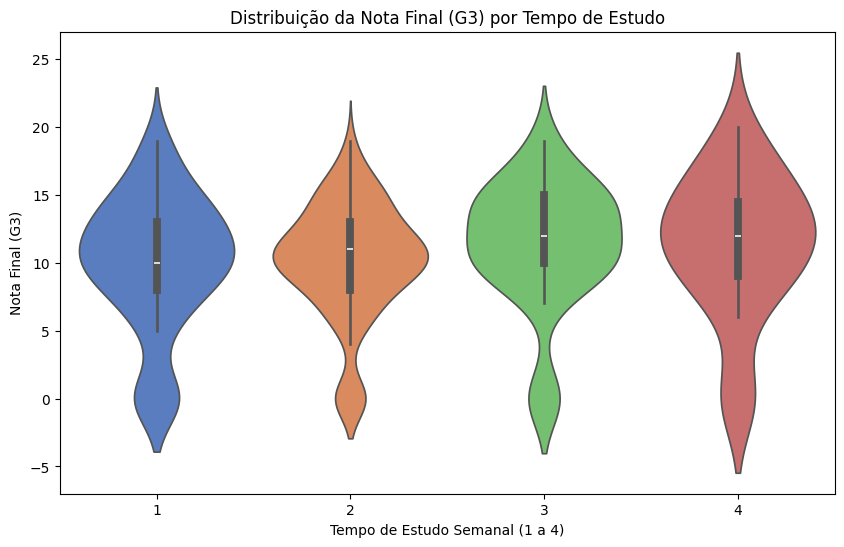

In [41]:
# Exemplo usando Violin Plot para Tempo de Estudo vs Nota Final
plt.figure(figsize=(10, 6))
sns.violinplot(x='studytime', y='G3', data=math_df, palette='muted')
plt.title('Distribuição da Nota Final (G3) por Tempo de Estudo')
plt.xlabel('Tempo de Estudo Semanal (1 a 4)')
plt.ylabel('Nota Final (G3)')
plt.show()

/tmp/ipykernel_1944/2690743130.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Dalc', y='G3', data=por_df, palette='flare')


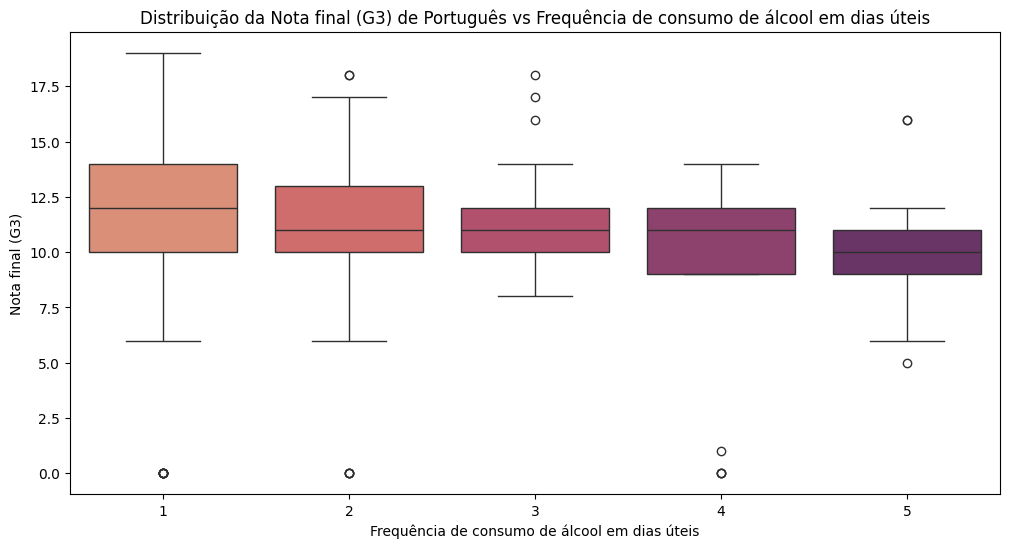

In [42]:
# Nota de Português dos alunos vs Frequência de consumo de álcool em dias úteis
plt.figure(figsize=(12, 6))
sns.boxplot(x='Dalc', y='G3', data=por_df, palette='flare')
plt.title('Distribuição da Nota final (G3) de Português vs Frequência de consumo de álcool em dias úteis')
plt.xlabel('Frequência de consumo de álcool em dias úteis')
plt.ylabel('Nota final (G3)')
plt.show()
# a relação aqui ficou muito boa!
# quanto menor a frequencia de consumo de alcool, maiores foram as notas de portugues e as medianas dos alunos

/tmp/ipykernel_1944/4288902403.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Medu', y='G3', data=por_df, palette='rocket')


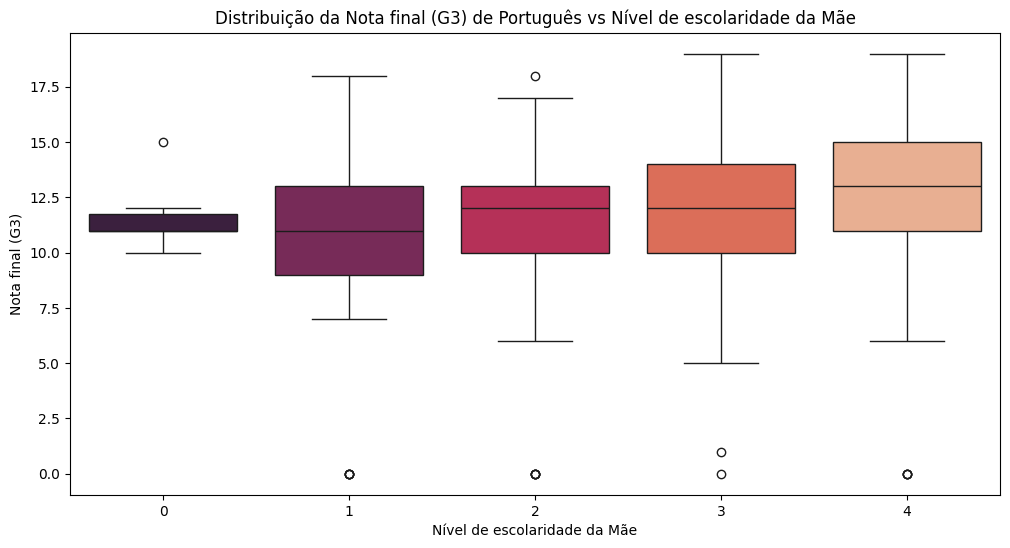

In [43]:
# Nota de Português dos alunos vs Nível de escolaridade da Mãe
plt.figure(figsize=(12, 6))
sns.boxplot(x='Medu', y='G3', data=por_df, palette='rocket')
plt.title('Distribuição da Nota final (G3) de Português vs Nível de escolaridade da Mãe')
plt.xlabel('Nível de escolaridade da Mãe')
plt.ylabel('Nota final (G3)')
plt.show()
# a relação também ficou muito boa!
# quanto maior o nivel de escolaridade da mae, maiores foram as notas de portugues e as medianas dos alunos

/tmp/ipykernel_1944/157737765.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Fedu', y='G3', data=por_df, palette='rocket')


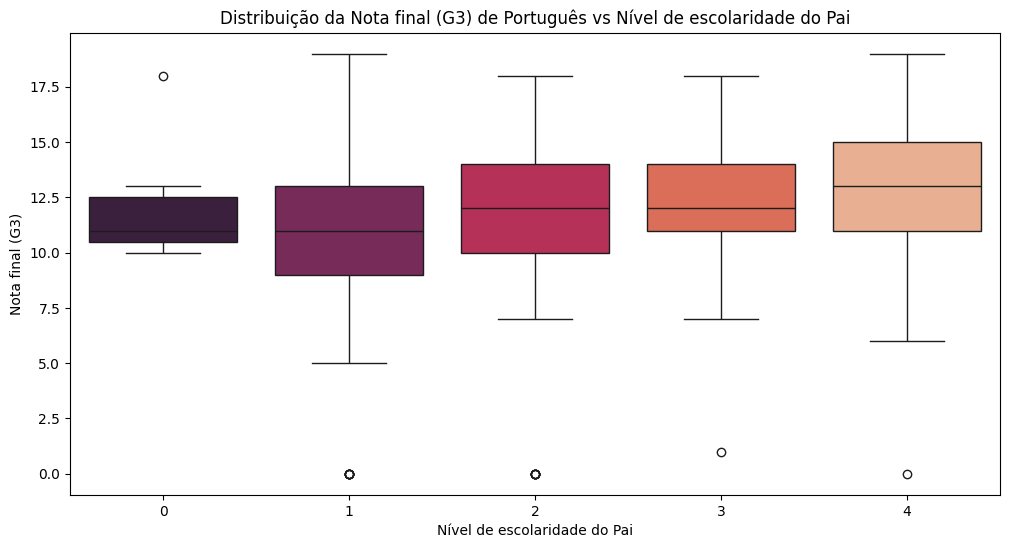

In [44]:
# Nota de Português dos alunos vs Nível de escolaridade do Pai
plt.figure(figsize=(12, 6))
sns.boxplot(x='Fedu', y='G3', data=por_df, palette='rocket')
plt.title('Distribuição da Nota final (G3) de Português vs Nível de escolaridade do Pai')
plt.xlabel('Nível de escolaridade do Pai')
plt.ylabel('Nota final (G3)')
plt.show()
# a relação também ficou muito boa!
# quanto maior o nivel de escolaridade do pai, maiores foram
# as medianas das notas de portugues

### Qual é a média, mediana e desvio padrão das notas em matemática e português?

In [45]:
# Matemática

media_notas_mat = math_df['G3'].mean()
mediana_notas_mat = math_df['G3'].median()
desvio_padrao_notas_mat = math_df['G3'].std()

print(f'Média das notas de Matemática: {media_notas_mat}')
print(f'Mediana das notas de Matemática: {mediana_notas_mat}')
print(f'Desvio padrão das notas de Matemática: {desvio_padrao_notas_mat}')

Média das notas de Matemática: 10.415189873417722
Mediana das notas de Matemática: 11.0
Desvio padrão das notas de Matemática: 4.5814426109978434


In [46]:
# Português

media_notas_por = por_df['G3'].mean()
mediana_notas_por = por_df['G3'].median()
desvio_padrao_notas_por = por_df['G3'].std()

print(f'Média das notas de Português: {media_notas_por}')
print(f'Mediana das notas de Português: {mediana_notas_por}')
print(f'Desvio padrão das notas de Português: {desvio_padrao_notas_por}')

Média das notas de Português: 11.906009244992296
Mediana das notas de Português: 12.0
Desvio padrão das notas de Português: 3.2306562428048045


## Correlação:

### Existe uma correlação significativa entre horas de estudo e notas finais? Calcule o coeficiente de correlação.

A correlação entre horas de estudo e notas finais é bem mais significativa nas notas de português (valor: ~0.25)

In [47]:
# Calcular a matriz de correlação de Matemática
corr = math_df[['studytime', 'G3']].corr()

print(f'Coeficiente de correlação entre horas de estudo e notas finais de Matemática: {corr.iloc[0, 1]}')
# horas de estudo vai de 1 a 4:
# 1 (<2 hours), 2 (2 to 5 hours), 3 (5 to 10 hours), or 4  (>10 hours)

Coeficiente de correlação entre horas de estudo e notas finais de Matemática: 0.09781968965319622


In [48]:
# Calcular a matriz de correlação de Português
corr = por_df[['studytime', 'G3']].corr()

print(f'Coeficiente de correlação entre horas de estudo e notas finais de Português: {corr.iloc[0, 1]}')
# horas de estudo vai de 1 a 4:
# 1 (<2 hours), 2 (2 to 5 hours), 3 (5 to 10 hours), or 4  (>10 hours)

Coeficiente de correlação entre horas de estudo e notas finais de Português: 0.24978868999886306


## Regressão Linear Simples:

### Construa um modelo de regressão linear simples para prever a nota final em matemática com base nas horas de estudo. Qual é a equação do modelo?

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

Pré-processamento dos Dados:

Converter variáveis categóricas em numéricas usando get_dummies()

In [50]:
math_df_encoded = pd.get_dummies(math_df, drop_first=True)

Definir Variáveis Independentes e Dependentes:

Vamos prever a nota final baseado em algumas características.

In [51]:
X = math_df_encoded[['studytime']] # Regressão Simples usa apenas 1 variável independente
y = math_df_encoded['G3']

Dividir os Dados em Conjuntos de Treinamento e Teste

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Criar e Treinar o Modelo de Regressão Linear

In [53]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Prever os Valores e Avaliar o Modelo

In [54]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')
# o modelo alcancou cerca de 72% de precisão

R²: -0.048176861902259116


Visualizar os Resultados

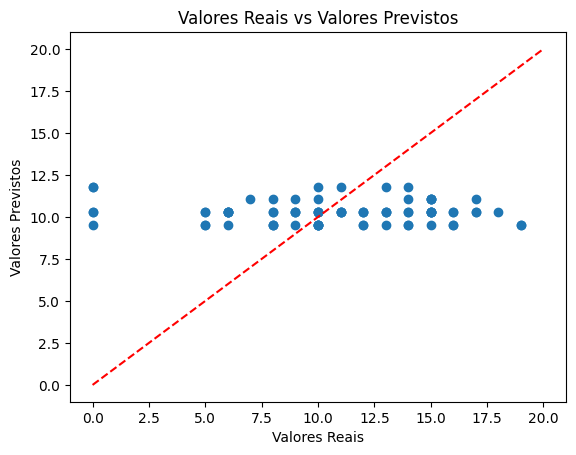

In [55]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()

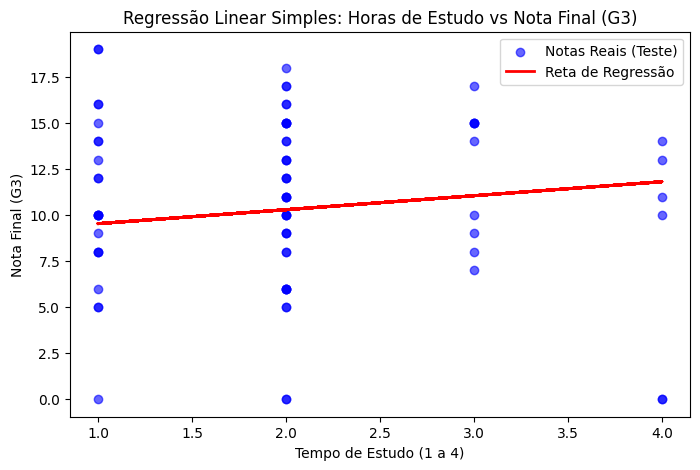

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Plota os pontos reais (Horas de estudo vs Nota real)
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Notas Reais (Teste)')

# Plota a linha de previsão do modelo
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Reta de Regressão')

plt.title('Regressão Linear Simples: Horas de Estudo vs Nota Final (G3)')
plt.xlabel('Tempo de Estudo (1 a 4)')
plt.ylabel('Nota Final (G3)')
plt.legend()
plt.show()

Equação do modelo

In [57]:
# 1. Extrai o intercepto e o coeficiente
intercepto = model.intercept_
coeficiente = model.coef_[0]

print("Equação da Regressão Linear Simples:")
print(f"Nota Final (G3) = {intercepto:.4f} + ({coeficiente:.4f} * studytime)")

Equação da Regressão Linear Simples:
Nota Final (G3) = 8.7727 + (0.7586 * studytime)


### Qual é o MSE (Erro Quadrático Médio) do modelo?

In [58]:
mse = mean_squared_error(y_test, y_pred)

print(f'Erro Quadrático Médio (MSE): {mse}')

Erro Quadrático Médio (MSE): 21.492916098598933


## Interpretação de Resultados:

### O que o coeficiente de regressão indica sobre a relação entre horas de estudo e notas finais em matemática?

O coeficiente positivo indica que há uma relação direta. Para cada aumento de nível no tempo de estudo do aluno, o modelo prevê um aumento de aproximadamente 0.76 pontos na nota final de matemática.

## Visualização:

### Crie um gráfico de dispersão mostrando a relação entre horas de estudo e notas finais em matemática, incluindo a linha de regressão.

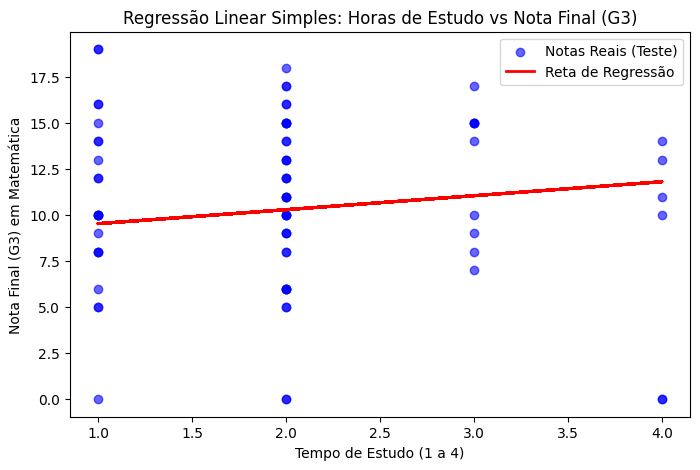

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Plota os pontos reais (Horas de estudo vs Nota real)
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Notas Reais (Teste)')

# Plota a linha de previsão do modelo
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Reta de Regressão')

plt.title('Regressão Linear Simples: Horas de Estudo vs Nota Final (G3)')
plt.xlabel('Tempo de Estudo (1 a 4)')
plt.ylabel('Nota Final (G3) em Matemática')
plt.legend()
plt.show()

## Regressão Linear com Todas as variáveis

Modelo para prever a nota de matemática

In [60]:
math_df_encoded = pd.get_dummies(math_df, drop_first=True)

In [88]:
X = math_df_encoded.drop('G3', axis=1)
y = math_df_encoded['G3']

In [89]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [90]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [91]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')

R²: 0.7241341236974022


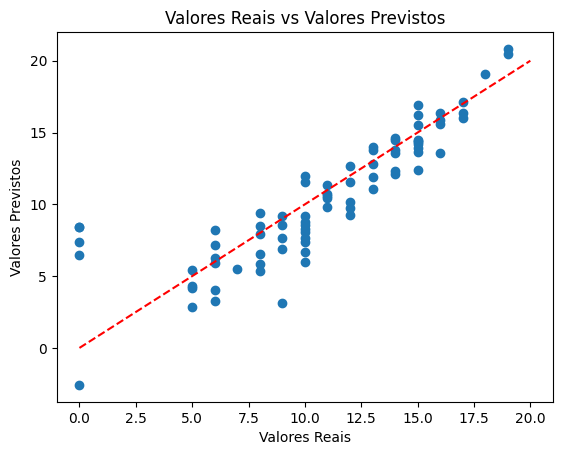

In [93]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()
# agora sim o modelo ficou muito melhor (72% de precisão)

#Análise Exploratória Inicial na base Insurance

In [61]:
insurance_df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/Mackenzie/4Semestre/AnaliseDeDados/Aula6/insurance.csv')

In [62]:
print(insurance_df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [63]:
print(insurance_df.tail())

      age     sex    bmi  children smoker     region     charges
1333   50    male  30.97         3     no  northwest  10600.5483
1334   18  female  31.92         0     no  northeast   2205.9808
1335   18  female  36.85         0     no  southeast   1629.8335
1336   21  female  25.80         0     no  southwest   2007.9450
1337   61  female  29.07         0    yes  northwest  29141.3603


In [64]:
insurance_df.shape
# esse dataset tem 1338 linhas e 7 colunas

(1338, 7)

In [65]:
print(insurance_df.info())

print('\n', insurance_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

                age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
m

In [66]:
print(insurance_df.isnull().sum())
# nenhum valor ausente

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [67]:
print('Linhas duplicadas no Dataframe Insurance:', insurance_df.duplicated().sum())

Linhas duplicadas no Dataframe Insurance: 1


In [68]:
insurance_df.drop_duplicates(inplace=True)

In [69]:
print('Linhas duplicadas no Dataframe Insurance:', insurance_df.duplicated().sum())

Linhas duplicadas no Dataframe Insurance: 0


# Dicionário de Dados para o dataset Insurance

| Variável | Descrição | Tipo | Mensuração | Valores |
| :--- | :--- | :--- | :--- | :--- |
| **age** | Idade do beneficiário principal. | Inteiro | Anos | 18 a 64 |
| **sex** | Gênero do contratante do seguro. | Categórico (Binário) | Texto | 'female' (feminino) ou 'male' (masculino) |
| **bmi** | Índice de Massa Corporal (IMC). | Numérico (Float) | kg/m² | 15.96 a 53.13 |
| **children** | Número de filhos/dependentes cobertos pelo plano de saúde. | Inteiro | Quantidade | 0 a 5 |
| **smoker** | Indicador se o segurado é fumante. | Categórico (Binário) | Texto | 'yes' (sim) ou 'no' (não) |
| **region** | Região de residência do beneficiário nos Estados Unidos. | Categórico | Texto | 'northeast', 'southeast', 'southwest', 'northwest' |
| **charges** | Custos médicos individuais faturados pelo seguro de saúde. | Numérico (Float) | Dólares (US$) | 1121.87 a 63770.43 |

# Questões sobre o Dataset Insurance

## Análise Descritiva:

Quais variáveis podem influenciar o custo do seguro? Analise as características como idade, IMC (Índice de Massa Corporal) e hábitos de fumo.

- A idade influencia, pois houve uma tendência de aumento de custo conforme a idade cresceu. Quanto mais velha a pessoa, maiores são os riscos estatísticos de problemas de saúde, encarecendo o seguro.
- Um Índice de Massa Corporal alto (especialmente acima de 30, que indica obesidade) está associado a doenças crônicas como diabetes e problemas cardíacos, aumentando o custo.
- O Hábito de fumo é a variável de maior impacto, fumantes têm um risco altíssimo de desenvolver doenças respiratórias e câncer, o que faz o prêmio do seguro disparar. Isso foi comprovado nas visualizações, pois a mediana do custo do seguro foi extremamente maior para os beneficiários que disseram que fumam.

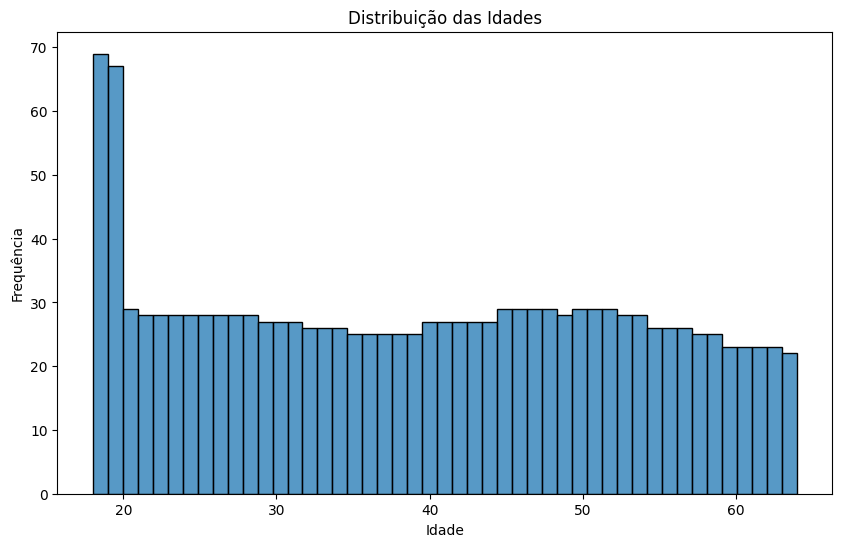

In [70]:
# Histograma da variável 'age'
plt.figure(figsize=(10, 6))
sns.histplot(insurance_df['age'], bins=47)
plt.title('Distribuição das Idades')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

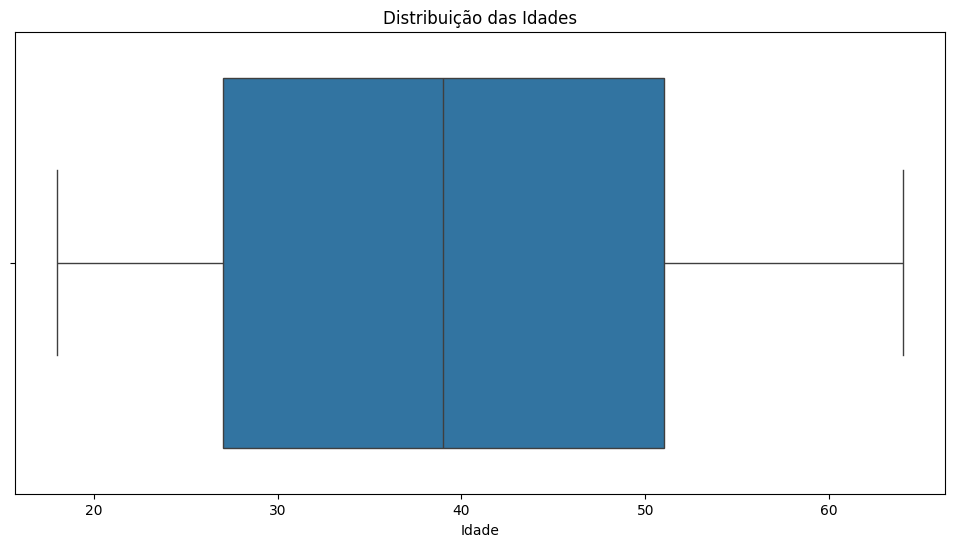

In [71]:
plt.figure(figsize=(12, 6))
sns.boxplot(insurance_df['age'],  orient='h')
plt.title('Distribuição das Idades')
plt.xlabel('Idade')
plt.show()

Insights:

- Todas as idades possuem de 20 a 30 clientes.
- As idades de 18 e 19 têm o dobro da média de clientes por idade.
- A mediana das idades é algo em torno de 38 ou 39 anos.

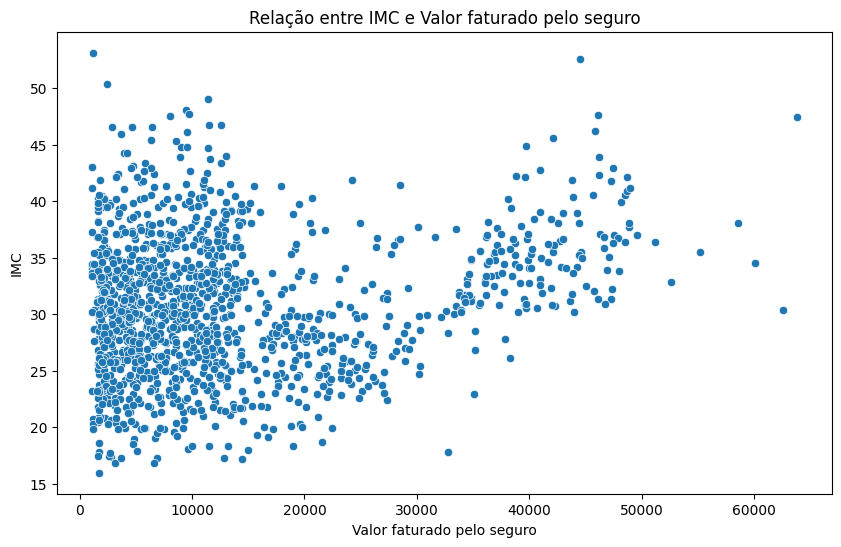

In [72]:
# Relação entre 'bmi' e 'charges'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='charges', y='bmi', data=insurance_df)
plt.title('Relação entre IMC e Valor faturado pelo seguro')
plt.xlabel('Valor faturado pelo seguro')
plt.ylabel('IMC')
plt.show()

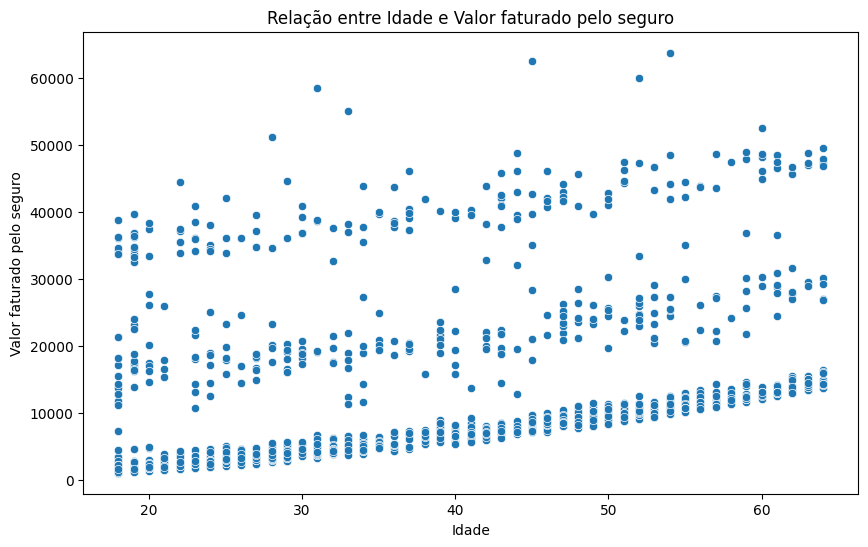

In [73]:
# Relação entre 'charges' e 'age'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='charges', data=insurance_df)
plt.title('Relação entre Idade e Valor faturado pelo seguro')
plt.xlabel('Idade')
plt.ylabel('Valor faturado pelo seguro')
plt.show()
# conforme as idades aumentam, o valor faturado também aumenta

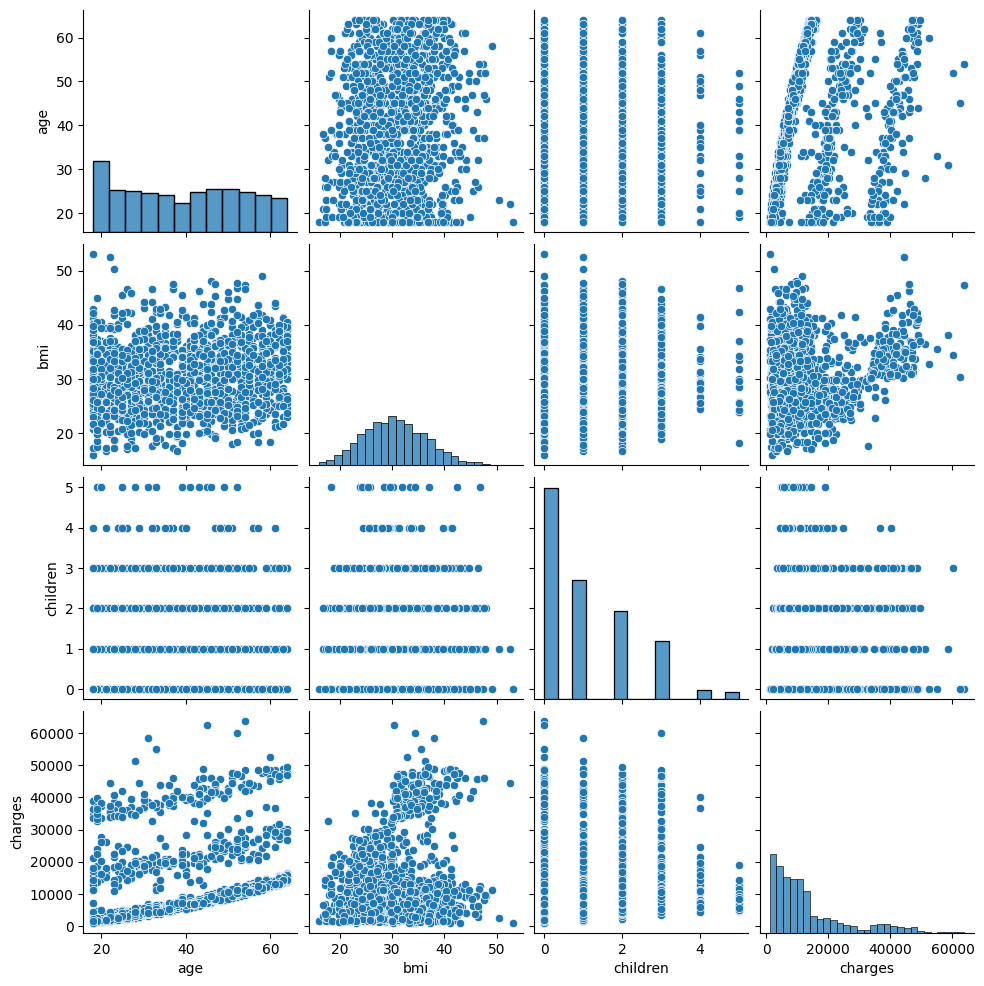

In [74]:
sns.pairplot(insurance_df)
plt.show()

/tmp/ipykernel_1944/169947646.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='charges', y='smoker', orient='h', data=insurance_df, palette='deep')


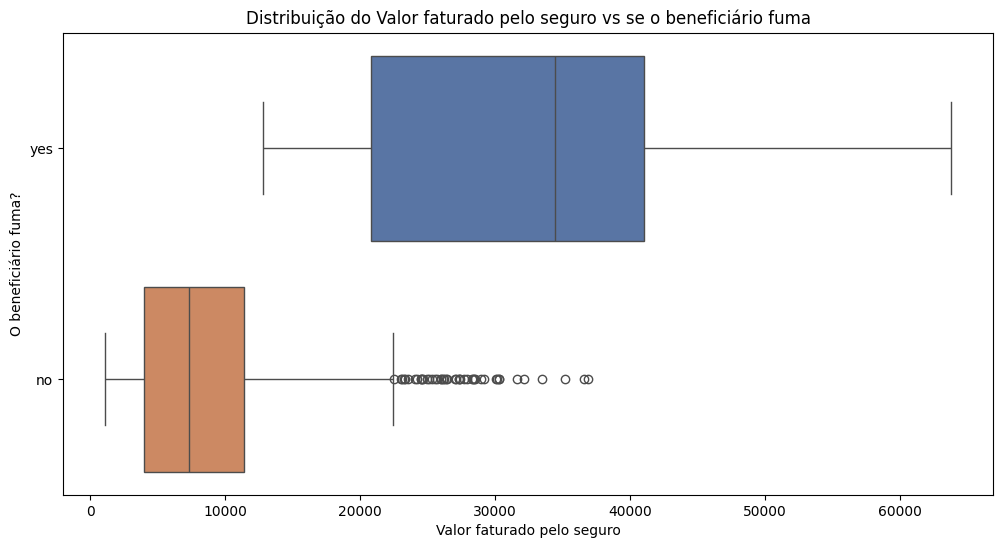

In [75]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='charges', y='smoker', orient='h', data=insurance_df, palette='deep')
plt.title('Distribuição do Valor faturado pelo seguro vs se o beneficiário fuma')
plt.xlabel('Valor faturado pelo seguro')
plt.ylabel('O beneficiário fuma?')
plt.show()

/tmp/ipykernel_1944/1929218193.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='smoker', y='charges', data=insurance_df, palette='deep')


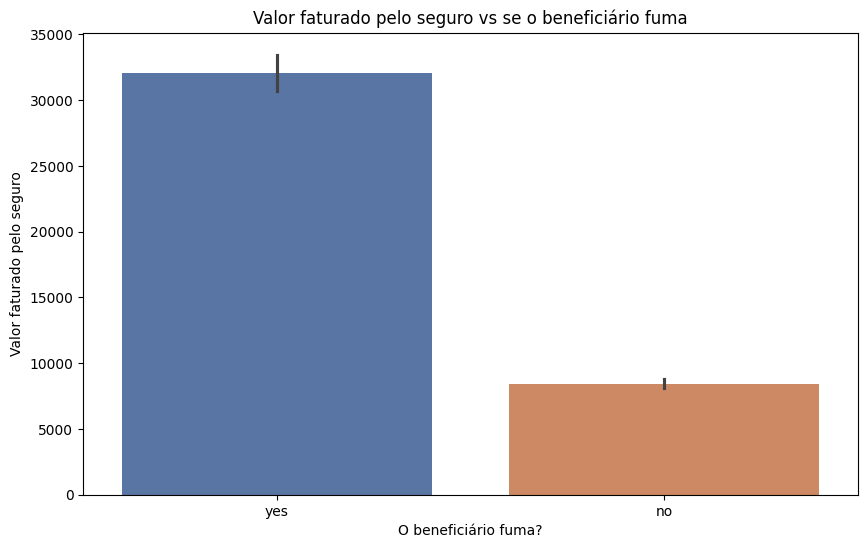

In [76]:
plt.figure(figsize=(10, 6))
sns.barplot(x='smoker', y='charges', data=insurance_df, palette='deep')
plt.title('Valor faturado pelo seguro vs se o beneficiário fuma')
plt.xlabel('O beneficiário fuma?')
plt.ylabel('Valor faturado pelo seguro')
plt.show()

Insights:

- Aqui pude perceber o valor faturado pelo seguro é muito maior com os beneficiários que fumam (a mediana é muito superior).

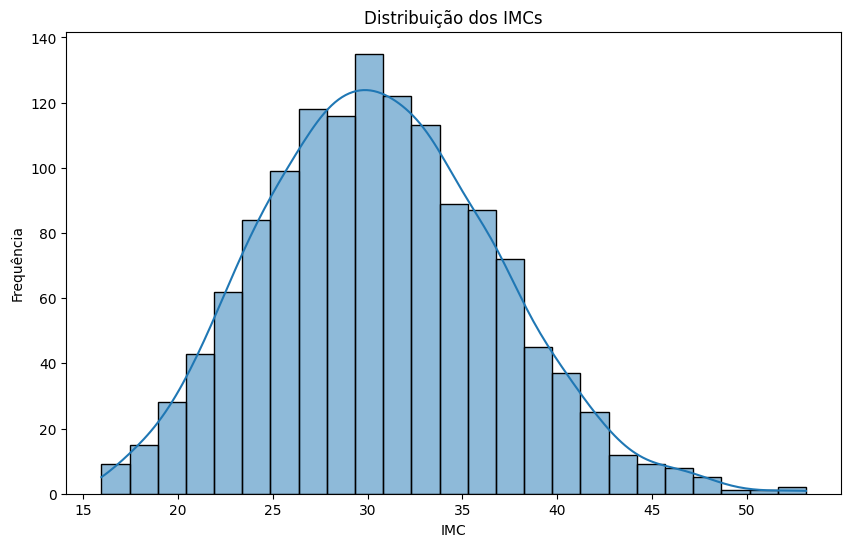

In [77]:
# Histograma da variável 'bmi'
plt.figure(figsize=(10, 6))
sns.histplot(insurance_df['bmi'], kde=True)
plt.title('Distribuição dos IMCs')
plt.xlabel('IMC')
plt.ylabel('Frequência')
plt.show()
# essa variável segue uma distribuição aproximadamente normal!

Insights:

- Os IMCs seguem uma distribuição aproximadamente normal.
- Os IMCs próximos de 30 são os que mais aparecem.

/tmp/ipykernel_1944/785369618.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='region', y='charges', data=insurance_df, palette='magma')


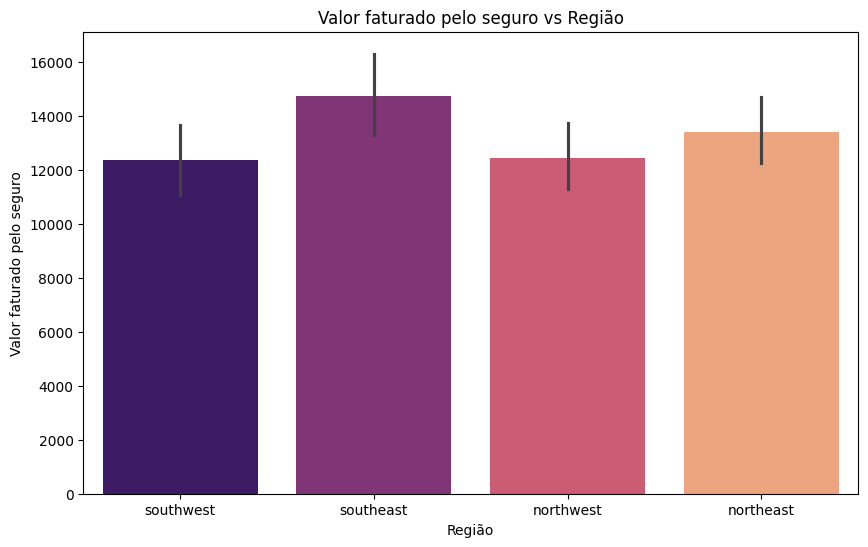

In [78]:
plt.figure(figsize=(10, 6))
sns.barplot(x='region', y='charges', data=insurance_df, palette='magma')
plt.title('Valor faturado pelo seguro vs Região')
plt.xlabel('Região')
plt.ylabel('Valor faturado pelo seguro')
plt.show()

Insights:

- A região dos EUA que mais trouxe faturamento ao serviço de seguro foi a região Sudeste (southeast).

## Correlação:

Calcule a matriz de correlação entre as variáveis independentes e o custo do seguro. Quais variáveis têm a maior correlação com o custo?

- Das variáveis numéricas, aquelas que possuem a maior correlação com o custo são: Fumante/smoker (0.79), Idade (0.3) e bmi/IMC (0.2)

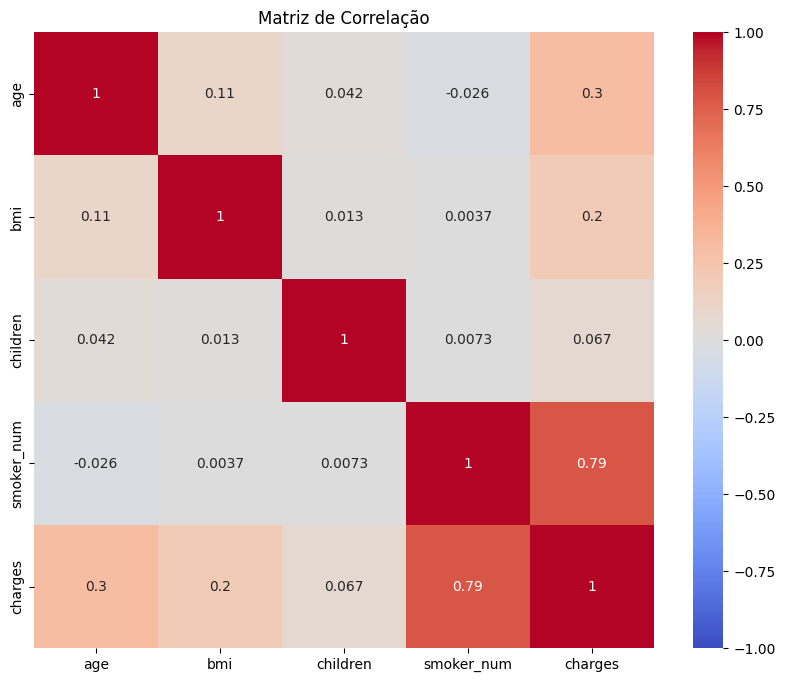

In [79]:
# Convertendo 'smoker' (yes/no) para números (1/0) para entrar na correlação
correlation_df = insurance_df.copy()
correlation_df['smoker_num'] = correlation_df['smoker'].apply(lambda x: 1 if x == 'yes' else 0)

# Calcular e visualizar a matriz de correlação usando o correlation_df correto
plt.figure(figsize=(10, 8))
correlacao = correlation_df[['age', 'bmi', 'children', 'smoker_num', 'charges']].corr()
sns.heatmap(correlacao, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação')
plt.show()

## Regressão Linear Simples:

### Construa um modelo de regressão linear simples para prever o custo do seguro com base no IMC. Qual é a equação do modelo?

Pré-processamento dos Dados:

Converter variáveis categóricas em numéricas usando get_dummies()

In [80]:
insurance_df_encoded = pd.get_dummies(insurance_df, drop_first=True)

Definir Variáveis Independentes e Dependentes:

Vamos prever o preço (price) baseado em algumas características.

In [81]:
X = insurance_df_encoded[['bmi']] # Regressão Simples usa apenas 1 variável independente
y = insurance_df_encoded['charges']

Dividir os Dados em Conjuntos de Treinamento e Teste

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Criar e Treinar o Modelo de Regressão Linear

In [83]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Qual é o R² do modelo e o que isso indica sobre o ajuste do modelo?

O R² do modelo vale cerca de 0.05, e isso indica que ele alcançou apenas 5% de precisão.

In [84]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')
# o modelo alcançou 5.2% de precisão!

R²: 0.051722611542952324


Visualizar os Resultados

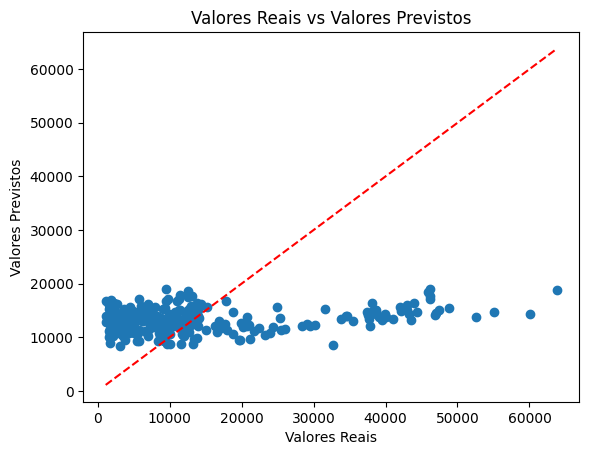

In [85]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()

Equação do modelo

In [86]:
# 1. Extrai o intercepto e o coeficiente
intercepto = model.intercept_
coeficiente = model.coef_[0]

print("Equação da Regressão Linear Simples:")
print(f"Custo do Seguro = {intercepto:.4f} + ({coeficiente:.4f} * IMC)")

Equação da Regressão Linear Simples:
Custo do Seguro = 2488.5712 + (345.1698 * IMC)


## Interpretação de Resultados:

O que o coeficiente de IMC no modelo de regressão indica? Como ele impacta o custo do seguro?

- Interpretação do Coeficiente de IMC:
O coeficiente do modelo indica a existência de uma relação direta e positiva entre o peso corporal e o valor cobrado pela apólice. Na prática, o coeficiente (que resulta em aproximadamente 345.1698) impacta o custo do seguro da seguinte forma: para cada 1 ponto de aumento no Índice de Massa Corporal (IMC) do indivíduo, o modelo prevê que o custo do seu seguro de saúde aumentará, em média, US$ 345.17

## Visualização:

Crie um gráfico de dispersão que mostre a relação entre IMC e custo do seguro, incluindo a linha de regressão.

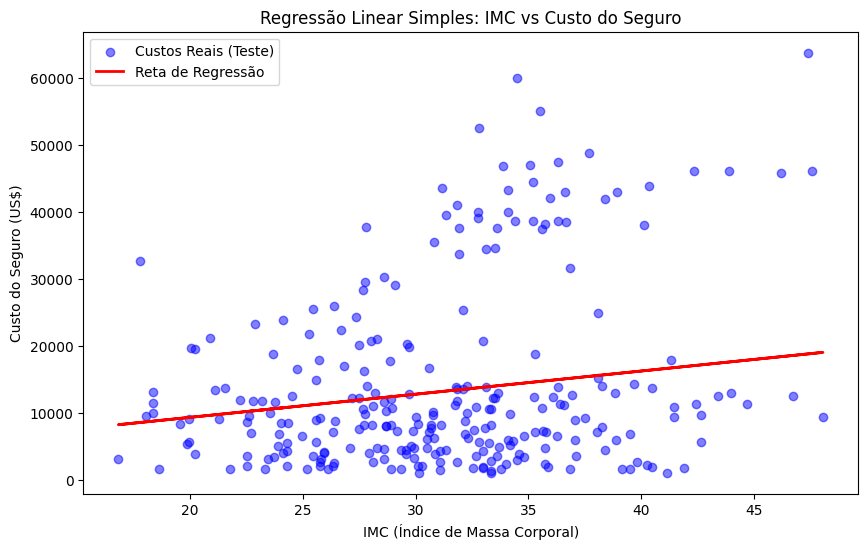

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plota os pontos reais (IMC vs Custo Real)
# Usamos alpha=0.5 para deixar os pontos meio transparentes e facilitar a visualização
plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Custos Reais (Teste)')

# Plota a linha de previsão do modelo (Reta de Regressão)
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Reta de Regressão')

# Adiciona títulos e rótulos
plt.title('Regressão Linear Simples: IMC vs Custo do Seguro')
plt.xlabel('IMC (Índice de Massa Corporal)')
plt.ylabel('Custo do Seguro (US$)')
plt.legend()

# Exibe o gráfico
plt.show()

## Regressão Linear com Todas as variáveis

In [106]:
insurance_df_encoded = pd.get_dummies(insurance_df, drop_first=True)

In [108]:
X = insurance_df_encoded.drop('charges', axis=1)
y = insurance_df_encoded['charges']

In [109]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [110]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [111]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')
# o modelo alcançou 81% de precisão!

R²: 0.8069287081198011


O R² do modelo vale cerca de 0.81, e isso indica que ele alcançou 81% de precisão.

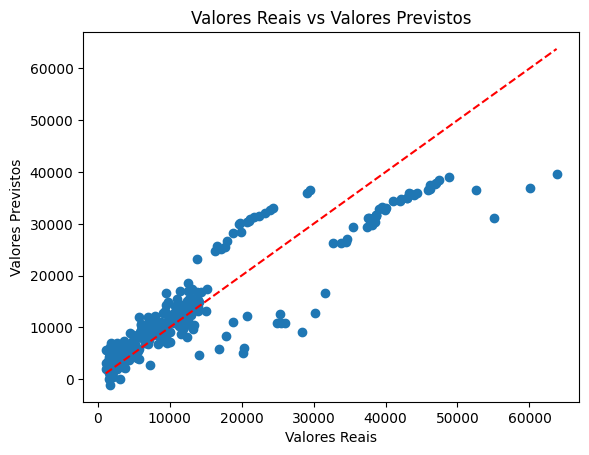

In [112]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()